In [2]:
import numpy as np                   
import pandas as pd              
import matplotlib.pyplot as plt         

from sklearn.linear_model import LinearRegression, Ridge, Lasso   
from sklearn.preprocessing import PolynomialFeatures, StandardScaler  # (mean=0, std=1)
from sklearn.pipeline import Pipeline 
from sklearn.tree import DecisionTreeRegressor      
from sklearn.neighbors import KNeighborsRegressor  
from sklearn.model_selection import LeaveOneOut, cross_val_score  
from sklearn.metrics import mean_squared_error, r2_score          

In [3]:
def rmse(y_true, y_pred):                                   
    return np.sqrt(mean_squared_error(y_true, y_pred))      

def train_rmse(model, X, y):                              
    model.fit(X, y)                                        
    return rmse(y, model.predict(X))                   

def loocv_rmse(model, X, y):                                
    scores = cross_val_score(model, X, y,                  
                             cv=LeaveOneOut(),          
                             scoring="neg_mean_squared_error")   
    return np.sqrt(-scores.mean())      

Part A : Exploring different hypothesis spaces
1. Explore the dataset

Dimensions: (10, 3)
       Study_Hours  Exam_Score
count     10.00000   10.000000
mean       5.50000   67.900000
std        3.02765   16.907921
min        1.00000   42.000000
25%        3.25000   56.000000
50%        5.50000   68.000000
75%        7.75000   80.250000
max       10.00000   91.000000


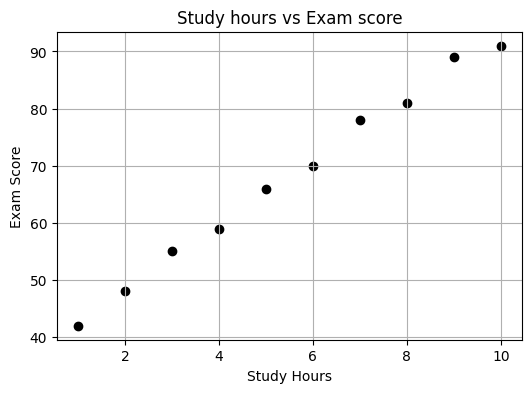

In [4]:
data = {                                                    
    "Student": ["S1","S2","S3","S4","S5","S6","S7","S8","S9","S10"],   
    "Study_Hours": [1,2,3,4,5,6,7,8,9,10],              
    "Exam_Score":  [42,48,55,59,66,70,78,81,89,91]         
}
df = pd.DataFrame(data)                                     

print("Dimensions:", df.shape)                           
print(df.describe())                                   

X = df[["Study_Hours"]].values                        
y = df["Exam_Score"].values                                 
plt.figure(figsize=(6,4))                      
plt.scatter(X, y, color="black")                         
plt.xlabel("Study Hours")                          
plt.ylabel("Exam Score")                                    
plt.title("Study hours vs Exam score")                  
plt.grid(True)                                              
plt.show()                                               

2. Fit different regression models

In [5]:
models = {                                                 
    "Linear Regression": LinearRegression(),      
    "Poly (deg 2)": Pipeline([("poly", PolynomialFeatures(degree=2, include_bias=False)),  
                              ("lr", LinearRegression())]),
    "Poly (deg 3)": Pipeline([("poly", PolynomialFeatures(degree=3, include_bias=False)),  
                              ("lr", LinearRegression())]), 
    "Tree (depth 1)": DecisionTreeRegressor(max_depth=1, random_state=0),  
    "Tree (depth 3)": DecisionTreeRegressor(max_depth=3, random_state=0),
    "KNN (k=3)": KNeighborsRegressor(n_neighbors=3)         
}


for name, model in models.items():                          
    model.fit(X, y)                                         

3. Compare the models

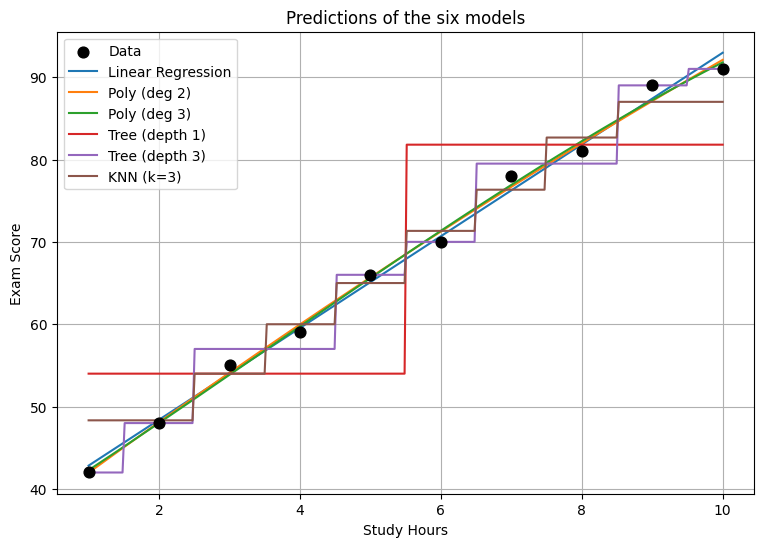

               Model  Training RMSE  Training R²
0  Linear Regression         1.1672       0.9947
1       Poly (deg 2)         1.0435       0.9958
2       Poly (deg 3)         1.0211       0.9959
3     Tree (depth 1)         8.0050       0.7509
4     Tree (depth 3)         1.1180       0.9951
5          KNN (k=3)         2.6562       0.9726


In [6]:
x_plot = np.linspace(1, 10, 300).reshape(-1, 1)             

plt.figure(figsize=(9,6))                          
plt.scatter(X, y, color="black", s=60, label="Data", zorder=5)  
for name, model in models.items():                       
    plt.plot(x_plot, model.predict(x_plot), label=name)     
plt.xlabel("Study Hours")                                
plt.ylabel("Exam Score")                                    
plt.title("Predictions of the six models")                 
plt.legend()                                             
plt.grid(True)                                             
plt.show()                                                 

rows = []                                                  
for name, model in models.items():                          
    y_pred = model.predict(X)                              
    rows.append({"Model": name,                            
                 "Training RMSE": rmse(y, y_pred),         
                 "Training R²": r2_score(y, y_pred)})       
table_A = pd.DataFrame(rows)                               
print(table_A.round(4))                                     

Part B : Investigating model complexity and generalization                                  
1. Prepare the training and test datasets using Leave-One-Out

In [7]:
loo = LeaveOneOut()                                         
print("Number of splits:", loo.get_n_splits(X))             

for i, (train_idx, test_idx) in enumerate(loo.split(X), start=1): 
    print(f"Iteration {i}")                                 
    print("  Train indices:", train_idx)                   
    print("  Test index   :", test_idx)                     
    print("  Train x:", X[train_idx].ravel())            
    print("  Test  x:", X[test_idx].ravel())                


Number of splits: 10
Iteration 1
  Train indices: [1 2 3 4 5 6 7 8 9]
  Test index   : [0]
  Train x: [ 2  3  4  5  6  7  8  9 10]
  Test  x: [1]
Iteration 2
  Train indices: [0 2 3 4 5 6 7 8 9]
  Test index   : [1]
  Train x: [ 1  3  4  5  6  7  8  9 10]
  Test  x: [2]
Iteration 3
  Train indices: [0 1 3 4 5 6 7 8 9]
  Test index   : [2]
  Train x: [ 1  2  4  5  6  7  8  9 10]
  Test  x: [3]
Iteration 4
  Train indices: [0 1 2 4 5 6 7 8 9]
  Test index   : [3]
  Train x: [ 1  2  3  5  6  7  8  9 10]
  Test  x: [4]
Iteration 5
  Train indices: [0 1 2 3 5 6 7 8 9]
  Test index   : [4]
  Train x: [ 1  2  3  4  6  7  8  9 10]
  Test  x: [5]
Iteration 6
  Train indices: [0 1 2 3 4 6 7 8 9]
  Test index   : [5]
  Train x: [ 1  2  3  4  5  7  8  9 10]
  Test  x: [6]
Iteration 7
  Train indices: [0 1 2 3 4 5 7 8 9]
  Test index   : [6]
  Train x: [ 1  2  3  4  5  6  8  9 10]
  Test  x: [7]
Iteration 8
  Train indices: [0 1 2 3 4 5 6 8 9]
  Test index   : [7]
  Train x: [ 1  2  3  4  5  6  7  

2. Explore different polynomial degrees                                                      
3. Evaluate generalization

In [8]:
degrees = [1, 2, 3, 5, 9]                                  

def make_poly(degree):                                      
    return Pipeline([("poly", PolynomialFeatures(degree=degree, include_bias=False)), 
                     ("lr", LinearRegression())])           

results_B = []                                              
for d in degrees:                                          
    model = make_poly(d)                                   
    tr = train_rmse(model, X, y)                            
    cv = loocv_rmse(make_poly(d), X, y)                 
    results_B.append({"Polynomial Degree": d,              
                      "Training RMSE": tr,              
                      "LOOCV RMSE": cv})                    
table_B = pd.DataFrame(results_B)                         
print(table_B.round(4))                                     

   Polynomial Degree  Training RMSE  LOOCV RMSE
0                  1         1.1672      1.5486
1                  2         1.0435      1.5728
2                  3         1.0211      2.0620
3                  5         0.8943      3.7070
4                  9         0.0002    261.9061


4. Analyze the results

Best degree by LOOCV: 1


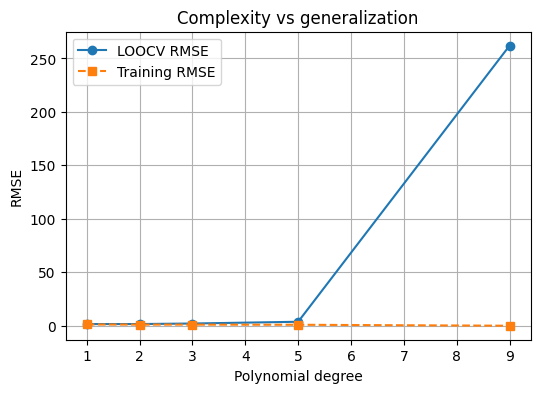

In [9]:
best_deg = table_B.loc[table_B["LOOCV RMSE"].idxmin(), "Polynomial Degree"]   
print("Best degree by LOOCV:", best_deg)                    

plt.figure(figsize=(6,4))                               
plt.plot(table_B["Polynomial Degree"], table_B["LOOCV RMSE"], "o-", label="LOOCV RMSE")      
plt.plot(table_B["Polynomial Degree"], table_B["Training RMSE"], "s--", label="Training RMSE") 
plt.xlabel("Polynomial degree")                             
plt.ylabel("RMSE")                                         
plt.title("Complexity vs generalization")                   
plt.legend()                                               
plt.grid(True)                                          
plt.show()                                                  

Part C : Investigating feature representation and regularization                            
1. Compare feature representations

In [10]:
rep_models = {                                             
    "Original (x)":       LinearRegression(),               
    "Poly (x, x², x³)":   make_poly(3),                     
    "Poly (x ... x⁵)":    make_poly(5)                      
}
for name, m in rep_models.items():                          
    print(f"{name:20s} LOOCV RMSE = {loocv_rmse(m, X, y):.4f}")   

Original (x)         LOOCV RMSE = 1.5486
Poly (x, x², x³)     LOOCV RMSE = 2.0620
Poly (x ... x⁵)      LOOCV RMSE = 3.7070


2. Investigate regularization

In [11]:
alphas = [0.01, 0.1, 1, 10]                                 

def make_reg_pipeline(reg_class, alpha, degree=5):          
    return Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),  
        ("scaler", StandardScaler()),                      
        ("reg", reg_class(alpha=alpha) if reg_class is Ridge   
                else reg_class(alpha=alpha, max_iter=100000))  
    ])

results_C = []                                              
for reg_name, reg_class in [("Ridge", Ridge), ("Lasso", Lasso)]:   
    for a in alphas:                                        
        cv = loocv_rmse(make_reg_pipeline(reg_class, a), X, y)     
        results_C.append({"Model": reg_name, "alpha": a, "LOOCV RMSE": cv})   
table_C_reg = pd.DataFrame(results_C)                      
print(table_C_reg.round(4))                                 

best_ridge = table_C_reg[table_C_reg.Model=="Ridge"].sort_values("LOOCV RMSE").iloc[0]   
best_lasso = table_C_reg[table_C_reg.Model=="Lasso"].sort_values("LOOCV RMSE").iloc[0]  
print("Best Ridge alpha:", best_ridge["alpha"])             
print("Best Lasso alpha:", best_lasso["alpha"])            

   Model  alpha  LOOCV RMSE
0  Ridge   0.01      2.1442
1  Ridge   0.10      1.8071
2  Ridge   1.00      3.5735
3  Ridge  10.00      7.2820
4  Lasso   0.01      1.7654
5  Lasso   0.10      1.6223
6  Lasso   1.00      1.9187
7  Lasso  10.00     11.8773
Best Ridge alpha: 0.1
Best Lasso alpha: 0.1


3. Compare the results

In [12]:
table_C = pd.DataFrame([                                    
    ["Linear Regression",     1,         "None", loocv_rmse(LinearRegression(), X, y)],            
    ["Polynomial Regression", 3,         "None", loocv_rmse(make_poly(3), X, y)],                  
    ["Polynomial Regression", 5,         "None", loocv_rmse(make_poly(5), X, y)],                 
    ["Ridge Regression",      5,         "L2",   best_ridge["LOOCV RMSE"]],                        
    ["Lasso Regression",      5,         "L1",   best_lasso["LOOCV RMSE"]],                        
    ["Decision Tree",         "depth 1", "None", loocv_rmse(DecisionTreeRegressor(max_depth=1, random_state=0), X, y)],
    ["Decision Tree",         "depth 3", "None", loocv_rmse(DecisionTreeRegressor(max_depth=3, random_state=0), X, y)],
    ["KNN",                   "k = 3",   "None", loocv_rmse(KNeighborsRegressor(n_neighbors=3), X, y)],
], columns=["Model", "Feature Degree", "Regularization", "LOOCV RMSE"])  
print(table_C.round(4))                                    

                   Model Feature Degree Regularization  LOOCV RMSE
0      Linear Regression              1           None      1.5486
1  Polynomial Regression              3           None      2.0620
2  Polynomial Regression              5           None      3.7070
3       Ridge Regression              5             L2      1.8071
4       Lasso Regression              5             L1      1.6223
5          Decision Tree        depth 1           None     13.4583
6          Decision Tree        depth 3           None      6.3659
7                    KNN          k = 3           None      6.0037


Part D : Final model comparison

                   Model Best config  Training RMSE  LOOCV RMSE
0      Linear Regression     default         1.1672      1.5486
1  Polynomial Regression    degree 2         1.0435      1.5728
2                  Ridge   alpha=0.1         1.0865      1.8071
3                  Lasso   alpha=0.1         1.0656      1.6223
4          Decision Tree     depth 3         1.1180      6.3659
5                    KNN         k=3         2.6562      6.0037


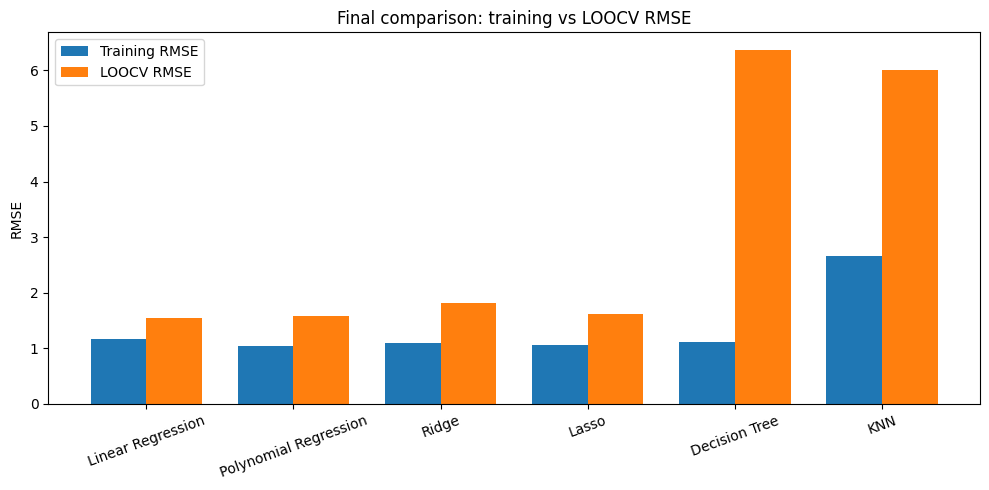

In [13]:
def best_of(candidates):                               
    scores = {n: loocv_rmse(m, X, y) for n, m in candidates.items()}   
    best = min(scores, key=scores.get)                      
    return best, candidates[best]                          

families = {}                                              

families["Linear Regression"] = ("default", LinearRegression())  

families["Polynomial Regression"] = best_of({              
    f"degree {d}": make_poly(d) for d in [2, 3, 5, 9]})

families["Ridge"] = best_of({                               
    f"alpha={a}": make_reg_pipeline(Ridge, a) for a in alphas})

families["Lasso"] = best_of({                               
    f"alpha={a}": make_reg_pipeline(Lasso, a) for a in alphas})

families["Decision Tree"] = best_of({                       
    f"depth {k}": DecisionTreeRegressor(max_depth=k, random_state=0) for k in [1, 3]})

families["KNN"] = ("k=3", KNeighborsRegressor(n_neighbors=3))     

final_rows = []                                            
for fam, (cfg, model) in families.items():                 
    final_rows.append({"Model": fam,                       
                       "Best config": cfg,                 
                       "Training RMSE": train_rmse(model, X, y),      
                       "LOOCV RMSE": loocv_rmse(model, X, y)})      
final_table = pd.DataFrame(final_rows)                     
print(final_table.round(4))                                

idx = np.arange(len(final_table))                          
w = 0.38                                                    
plt.figure(figsize=(10,5))                                  
plt.bar(idx - w/2, final_table["Training RMSE"], w, label="Training RMSE")   
plt.bar(idx + w/2, final_table["LOOCV RMSE"], w, label="LOOCV RMSE")         
plt.xticks(idx, final_table["Model"], rotation=20)         
plt.ylabel("RMSE")                                         
plt.title("Final comparison: training vs LOOCV RMSE")      
plt.legend()                                             
plt.tight_layout()                                         
plt.show()                                                 

Conclusion

This practical session examined how model complexity, feature representation, and regularization affect generalization on a small dataset of ten students, using Leave-One-Out Cross-Validation (LOOCV) as the common evaluation strategy.

1. Influence of model complexity. Increasing the polynomial degree or the tree depth always reduces the training RMSE, because a larger hypothesis space can fit the training observations more closely. At degree 9, the polynomial interpolates all ten points and the training RMSE approaches zero. However, the LOOCV RMSE does not follow the same trend: after a certain complexity it increases sharply, which is a clear sign of overfitting. A low training error therefore does not guarantee good predictions on unseen data.

2. Influence of feature representation. The relationship between study hours and exam scores is close to linear. As a result, the original representation (x) and low-degree polynomial representations generalize well, while adding higher-order terms (x⁴, x⁵) increases the model’s variance without capturing any additional real structure. The representation should match the true complexity of the underlying relationship.

3. Influence of regularization. Ridge (L2) and Lasso (L1) constrain the size of the coefficients of the degree-5 polynomial model. This reduces variance and generally improves LOOCV performance compared with the unregularized degree-5 model. Lasso can additionally set some coefficients exactly to zero, acting as a form of feature selection. The strength of the regularization (alpha) must be chosen carefully: too small has little effect, and too large causes underfitting.

4. Overall result. The best model is the one with the lowest LOOCV RMSE, not the lowest training RMSE. In this experiment, the best generalizing models are the simple or regularized ones (linear, low-degree polynomial, Ridge), while very flexible models (degree-9 polynomial, deep trees) overfit. This confirms the bias-variance trade-off: good generalization comes from choosing the right level of complexity, not the maximum one.